# Chapter 16: Visualizing Data

In [1]:
import polars as pl
pl.__version__  # The book is built with Polars version 1.20.0

'2.0.0'

## NYC Bike Trips

In [2]:
trips = pl.read_parquet("data/citibike/*.parquet")

print(trips[:, :4])
print(trips[:, 4:7])
print(trips[:, 7:11])
print(trips[:, 11:])

shape: (2_638_971, 4)
┌───────────┬────────────┬─────────────────────────┬─────────────────────────┐
│ bike_type ┆ rider_type ┆ datetime_start          ┆ datetime_end            │
│ ---       ┆ ---        ┆ ---                     ┆ ---                     │
│ cat       ┆ cat        ┆ datetime[μs]            ┆ datetime[μs]            │
╞═══════════╪════════════╪═════════════════════════╪═════════════════════════╡
│ electric  ┆ member     ┆ 2024-03-01 00:00:02.490 ┆ 2024-03-01 00:27:39.295 │
│ electric  ┆ member     ┆ 2024-03-01 00:00:04.120 ┆ 2024-03-01 00:09:29.384 │
│ electric  ┆ casual     ┆ 2024-03-01 00:00:05.209 ┆ 2024-03-01 00:03:34.692 │
│ classic   ┆ member     ┆ 2024-03-01 00:00:05.259 ┆ 2024-03-01 00:31:02.219 │
│ electric  ┆ member     ┆ 2024-03-01 00:00:09.837 ┆ 2024-03-01 00:11:42.320 │
│ …         ┆ …          ┆ …                       ┆ …                       │
│ classic   ┆ member     ┆ 2024-03-31 23:55:29.002 ┆ 2024-03-31 23:57:10.376 │
│ classic   ┆ member     ┆ 202

## Built-In Plotting with Altair

### Introducing Altair

In [3]:
import altair as alt

### Methods in the Plot Namespaces

### Plotting DataFrames

In [4]:
trips_speed = trips.select(
    pl.col("distance"),
    pl.col("duration").dt.total_seconds() / 3600,  
    pl.col("bike_type"),
).with_columns(speed=pl.col("distance") / pl.col("duration"))

trips_speed

distance,duration,bike_type,speed
f64,f64,cat,f64
4.842569,0.46,"""electric""",10.527324
2.659582,0.156944,"""electric""",16.94601
0.398795,0.058056,"""electric""",6.869194
5.09153,0.515556,"""classic""",9.875812
3.08728,0.192222,"""electric""",16.060992
…,…,…,…
0.272175,0.028056,"""classic""",9.701291
0.492269,0.058333,"""classic""",8.438897
0.406138,0.029444,"""classic""",13.793378


In [ ]:
# This raises a MaxRowsError:
# trips_speed.plot.scatter(
#    x="distance",
#    y="duration",
#    color="bike_type:N",
# )

In [5]:
trips_speed = (
    trips.filter(pl.col("station_start") == "W 70 St & Amsterdam Ave")
    .select(
        pl.col("distance"),
        pl.col("duration").dt.total_seconds() / 3600,
        pl.col("bike_type"),
    )
    .with_columns(speed=pl.col("distance") / pl.col("duration"))
)

trips_speed

distance,duration,bike_type,speed
f64,f64,cat,f64
0.596344,0.039167,"""electric""",15.225797
1.134568,0.153611,"""classic""",7.385977
4.586869,0.492778,"""electric""",9.30819
0.839622,0.046111,"""electric""",18.208666
0.351954,0.027778,"""electric""",12.670335
…,…,…,…
2.850176,0.172778,"""electric""",16.496196
0.590008,0.060833,"""classic""",9.698761
1.821509,0.133611,"""electric""",13.632919


In [10]:
chart = trips_speed.plot.scatter(
    x="distance",
    y="duration",
    color="bike_type:N", 
    size="speed" 
)

display(chart)

alt.Chart(...)

### Too Large to Handle

In [11]:
import altair as alt

alt.data_transformers.disable_max_rows()

DataTransformerRegistry.enable('default')

In [12]:
alt.data_transformers.enable("vegafusion")

DataTransformerRegistry.enable('vegafusion')

In [13]:
trips_type_counts = trips.group_by("rider_type", "bike_type").len()
trips_type_counts

rider_type,bike_type,len
cat,cat,u32
"""casual""","""electric""",294679
"""member""","""electric""",1412598
"""member""","""classic""",811168
"""casual""","""classic""",120526


In [14]:
from IPython.display import display

chart = trips_type_counts.plot.bar(
    x="rider_type", y="len", fill="bike_type:N"
).properties(
    width=300,
)
display(chart)

ImportError: The "vegafusion" data transformer and chart.transformed_data feature requires
version 2.0.3 or greater of the 'vegafusion' package.
This can be installed with pip using:
    pip install "vegafusion>=2.0.3"
or conda:
    conda install -c conda-forge "vegafusion>=2.0.3"

ImportError: vegafusion

alt.Chart(...)

### Plotting Series

In [ ]:
trips_speed["distance"].plot.kde()

In [ ]:
trips_speed["distance"].plot.hist()

In [ ]:
trips_hour_num_speed = (
    trips.sort("datetime_start")
    .group_by_dynamic("datetime_start", every="1h")
    .agg(
        num_trips=pl.len(),
        speed=(
            pl.col("distance") / (pl.col("duration").dt.total_seconds() / 3600)
        ).median(),
    )
    .filter(pl.col("datetime_start") > pl.date(2024, 3, 26))
)

trips_hour_num_speed

In [ ]:
trips_hour_num_speed.plot.line(x="datetime_start", y="num_trips")

## pandas-Like Plotting with hvPlot

### Introducing hvPlot

In [ ]:
import hvplot.polars

### A First Plot

In [ ]:
trips_speed.hvplot.scatter(
    x="distance",
    y="duration",
    color="bike_type",  
    xlabel="distance (km)",
    ylabel="duration (h)",  
    ylim=(0, 2),  
)

### Methods in the hvPlot Namespace

### pandas as Backup

In [ ]:
trips_per_day_hour = (
    trips.sort("datetime_start")
    .group_by_dynamic("datetime_start", every="1h")
    .agg(pl.len())
)

In [ ]:
# This raises a ValueError:
# trips_per_day_hour.hvplot.heatmap(
#     x="datetime_start.hour", y="datetime_start.day", C="len", cmap="reds"
# )

In [ ]:
import hvplot.pandas

trips_per_day_hour.to_pandas().hvplot.heatmap(
    x="datetime_start.hour", y="datetime_start.day", C="len", cmap="reds"
)

### Manual Transformations

In [ ]:
trips_type_counts.hvplot.bar(
    x="rider_type",
    y="len",
    by="bike_type",
    ylabel="count",
    stacked=True,
    color=["orange", "green"],
)

### Changing the Plotting Backend

In [ ]:
import hvplot

hvplot.extension("matplotlib")

In [ ]:
trips_type_counts.hvplot.bar(
    x="rider_type",
    y="len",
    by="bike_type",
    ylabel="count",
    stacked=True,
    color=["orange", "green"],
)

In [ ]:
hvplot.extension("bokeh")

### Plotting Points on a Map

In [ ]:
trips.hvplot.points(
    x="lon_start",
    y="lat_start",
    datashade=True,
    geo=True,
    tiles="CartoLight",
    width=800,
    height=600,
)

### Composing Plots

In [ ]:
(
    trips_hour_num_speed.hvplot.line(x="datetime_start", y="num_trips")
    + trips_hour_num_speed.hvplot.line(x="datetime_start", y="speed")
).cols(  
    1
)

In [ ]:
(
    trips_hour_num_speed.hvplot.line(x="datetime_start", y="num_trips")
    * trips_hour_num_speed.filter(pl.col("num_trips") > 9000).hvplot.scatter(
        x="datetime_start", y="num_trips", c="red", s=50
    )
)

### Adding Interactive Widgets

In [ ]:
trips_per_hour = (
    trips.sort("datetime_start")
    .group_by_dynamic("datetime_start", group_by="borough_start", every="1h")
    .agg(pl.len())
    .with_columns(date=pl.col("datetime_start").dt.date())
)
trips_per_hour

In [ ]:
trips_per_hour.hvplot.line(
    x="datetime_start",
    by="borough_start",
    groupby="date",
    widget_location="left_top",
)

## Publication-Quality Graphics with plotnine

### Introducing plotnine

In [15]:
from plotnine import *

### Plots for Exploration

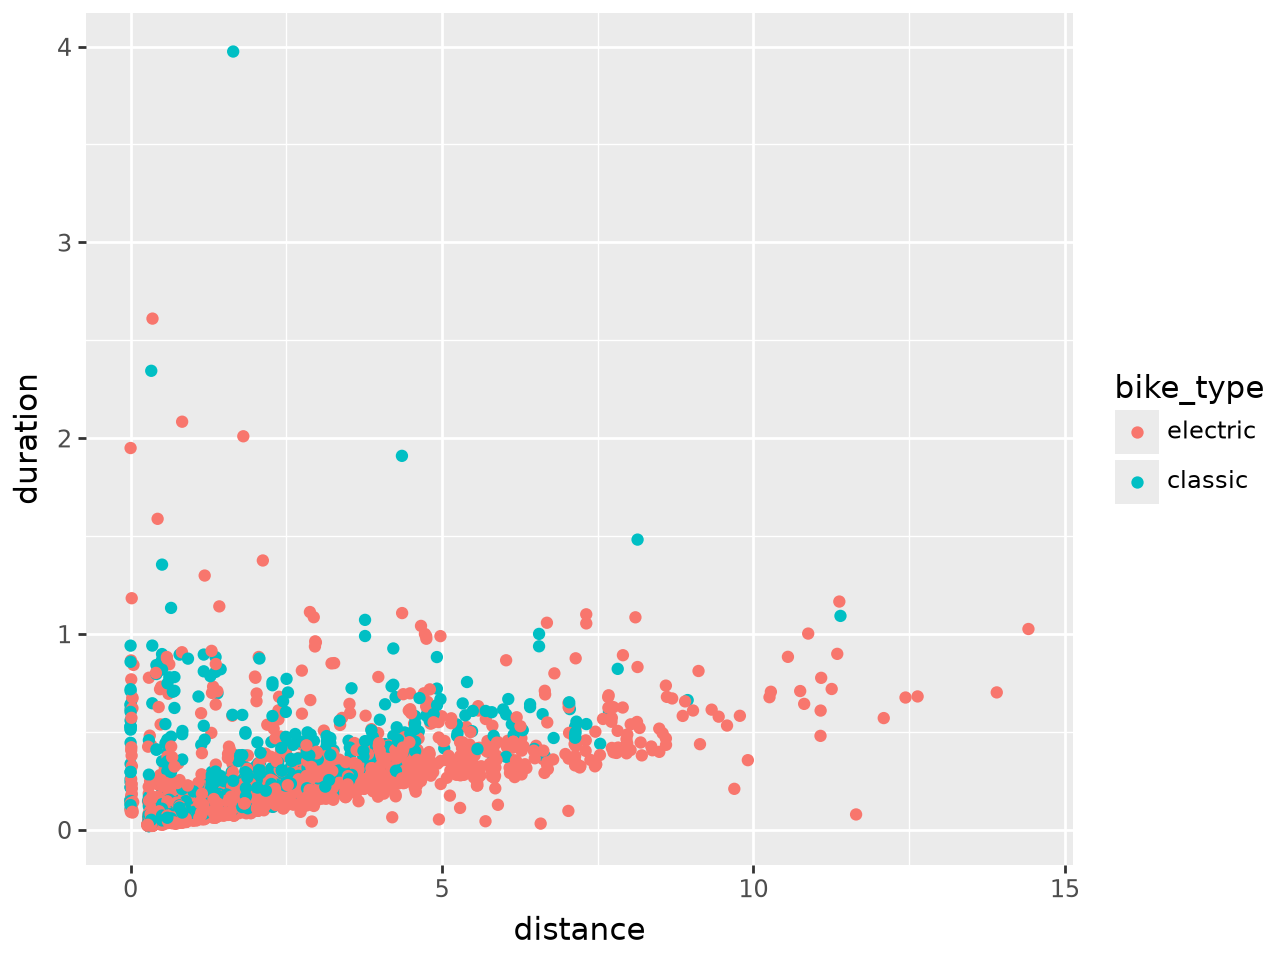

In [16]:
(
    ggplot(trips_speed, aes(x="distance", y="duration", color="bike_type"))
    + geom_point()  
)

d:\Programs\anaconda3\envs\py314\Lib\site-packages\plotnine\stats\stat_bin.py:112: PlotnineWarning: 'stat_bin()' using 'bins = 72'. Pick better value with 'binwidth'.


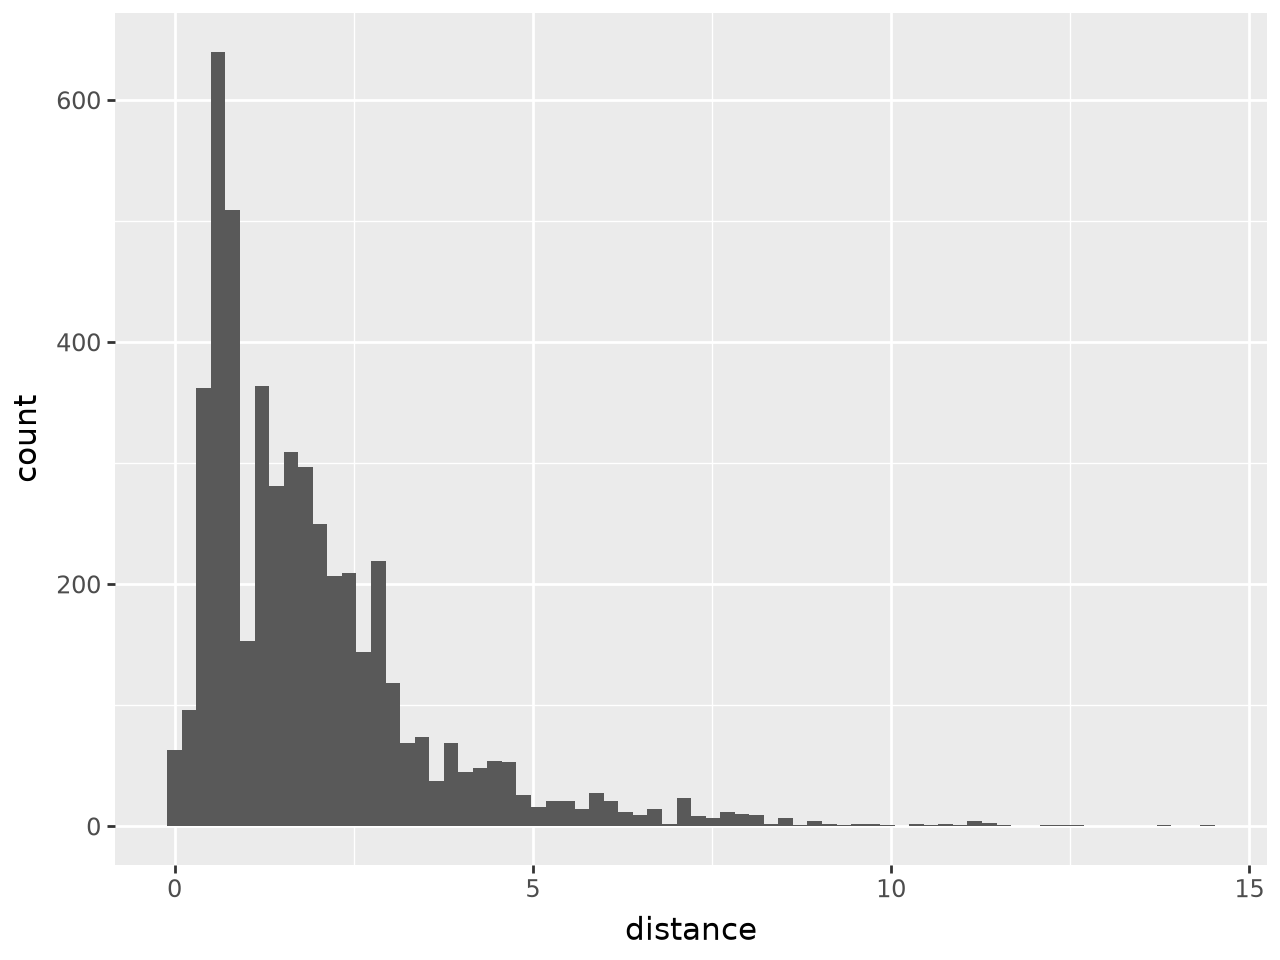

In [17]:
ggplot(trips_speed, aes(x="distance")) + geom_histogram()

In [ ]:
ggplot(trips, aes(x="rider_type", fill="bike_type")) + geom_bar()

In [ ]:
ggplot(trips_speed, aes(x="distance", fill="bike_type")) + geom_density(
    alpha=0.7, color="none"
)

In [ ]:
(
    ggplot(trips_hour_num_speed, aes(x="datetime_start", y="num_trips"))
    + geom_line(size=1, color="steelblue")
    + geom_point(
        data=trips_hour_num_speed.filter(pl.col("num_trips") > 9000),
        color="red",
        size=4,
    )
)

### Plots for Communication

In [18]:
trips_speed = (
    trips.group_by("neighborhood_start", "neighborhood_end")
    .agg(
        pl.col("duration").dt.total_seconds().median() / 60,
        pl.col("distance").median(),
        pl.col("borough_start").first(),
        pl.col("borough_end").first(),
        pl.len(),
    )
    .filter(
        (pl.col("len") > 30)
        & (pl.col("distance") > 0.2)
        & (pl.col("neighborhood_start") != pl.col("neighborhood_end")),
    )
    .with_columns(speed=pl.col("distance") / pl.col("duration"))
    .sort("borough_start")
)
trips_speed

neighborhood_start,neighborhood_end,duration,distance,borough_start,borough_end,len,speed
str,str,f64,f64,str,str,u32,f64
"""Morrisania""","""Crotona Park""",4.616667,0.942718,"""Bronx""","""Bronx""",82,0.204199
"""Kingsbridge""","""Belmont""",10.533333,2.203046,"""Bronx""","""Bronx""",118,0.20915
"""Longwood""","""Fordham""",17.933333,4.430618,"""Bronx""","""Bronx""",141,0.24706
"""Longwood""","""Melrose""",5.283333,0.987118,"""Bronx""","""Bronx""",407,0.186836
"""Longwood""","""Morris Heights""",17.55,3.411044,"""Bronx""","""Bronx""",83,0.194361
…,…,…,…,…,…,…,…
"""Ridgewood""","""Jackson Heights""",22.891667,5.856876,"""Queens""","""Queens""",32,0.255852
"""Long Island City""","""Midtown""",17.316667,2.935654,"""Queens""","""Manhattan""",1498,0.169528
"""Long Island City""","""Financial District""",36.883333,6.648072,"""Queens""","""Manhattan""",64,0.180246


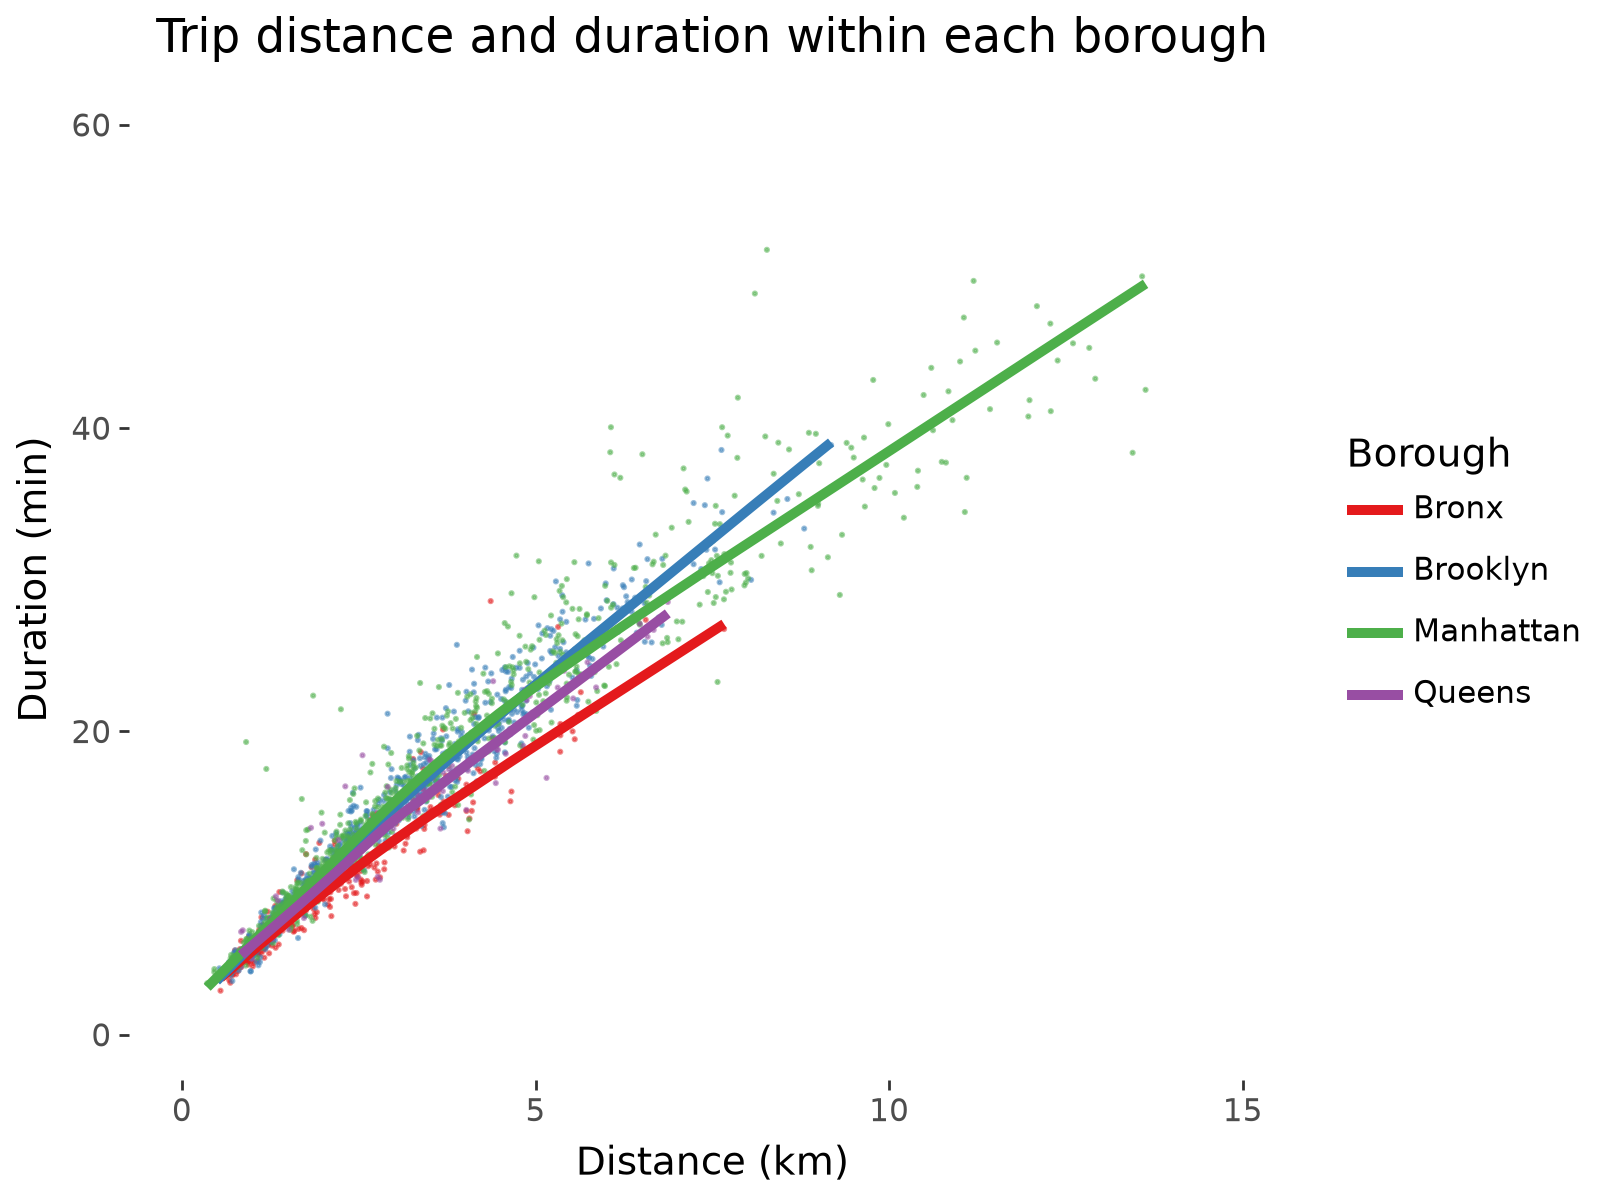

In [19]:
(
    ggplot(
        data=trips_speed.filter(
            pl.col("borough_start") == pl.col("borough_end")
        ),
        mapping=aes(x="distance", y="duration", color="borough_end"),
    )
    + geom_point(size=0.25, alpha=0.5)
    + geom_smooth(method="lowess", size=2, se=False, alpha=0.8)
    + xlim(0, 15)  
    + ylim(0, 60)
    + scale_color_brewer(type="qualitative", palette="Set1")
    + labs(
        title="Trip distance and duration within each borough",
        x="Distance (km)",
        y="Duration (min)",
        color="Borough",
    )
    + theme_tufte(base_size=14)
    + theme(
        figure_size=(8, 6),
        plot_background=element_rect(color="#ffffff"),
    )
)

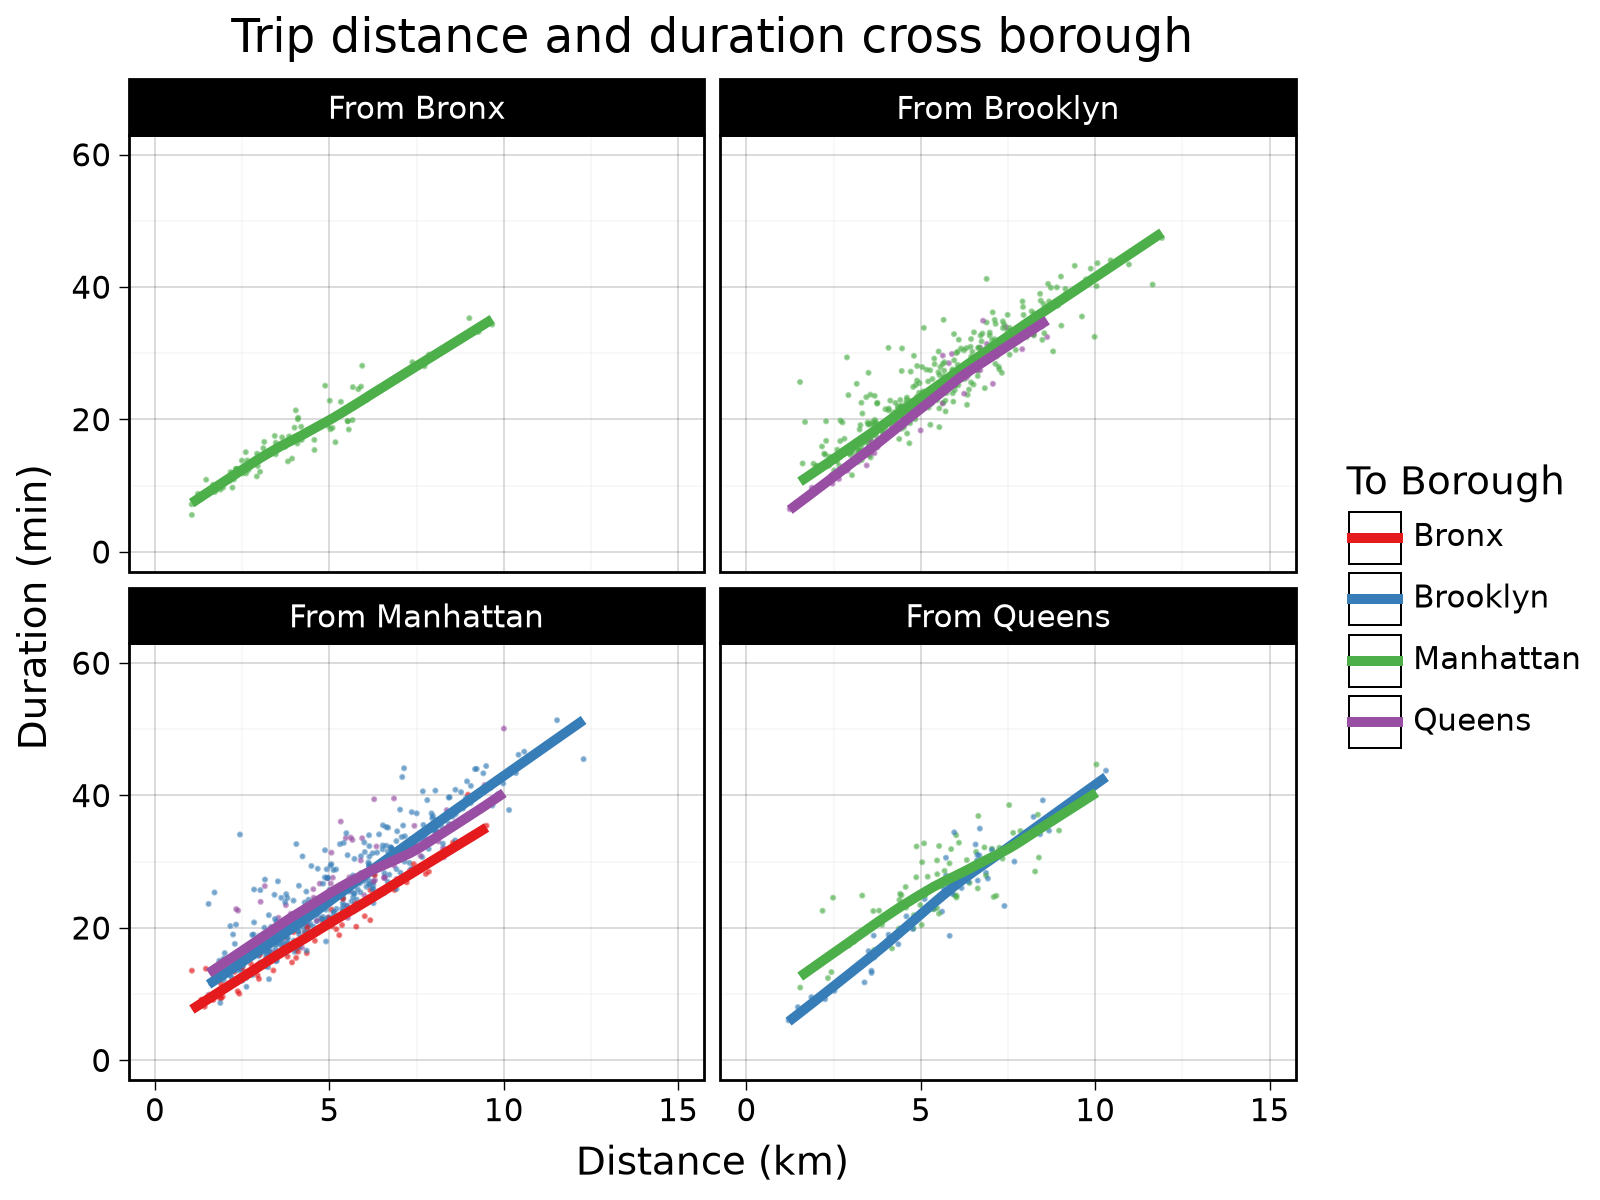

In [20]:
(
    ggplot(
        data=trips_speed.filter(
            pl.col("borough_start") != pl.col("borough_end")
        ).with_columns(
            ("From " + pl.col("borough_start")).alias("borough_start")
        ),
        mapping=aes(x="distance", y="duration", color="borough_end"),
    )
    + geom_point(size=0.25, alpha=0.5)
    + geom_smooth(method="lowess", size=2, se=False, alpha=0.8)
    + xlim(0, 15)
    + ylim(0, 60)
    + scale_color_brewer(type="qualitative", palette="Set1")
    + facet_wrap("borough_start")
    + labs(
        title="Trip distance and duration cross borough",
        x="Distance (km)",
        y="Duration (min)",
        color="To Borough",
    )
    + theme_linedraw(base_size=14)
    + theme(figure_size=(8, 6))
)

## Styling DataFrames With Great Tables

In [21]:
import polars.selectors as cs

busiest_stations = (
    trips.group_by(  
        station=pl.col("station_start"), date=pl.col("datetime_start").dt.date()
    )
    .agg(
        borough=pl.col("borough_start").first(),
        neighborhood=pl.col("neighborhood_start").first(),
        num_rides=pl.len(),
        percent_member=(pl.col("rider_type") == "member").mean(),
        percent_electric=(pl.col("bike_type") == "electric").mean(),
    )
    .sort("date")
    .group_by("station")
    .agg(
        cs.string().first(),
        cs.numeric().mean(),
        pl.col("num_rides").alias("rides_per_day"),  
    )
    .sort("num_rides", descending=True)
    .group_by("borough", maintain_order=True)
    .head(3)
)

busiest_stations

borough,station,neighborhood,num_rides,percent_member,percent_electric,rides_per_day
str,str,str,f64,f64,f64,list[u32]
"""Manhattan""","""W 21 St & 6 Ave""","""Chelsea""",354.16129,0.913765,0.583606,"[325, 88, … 306]"
"""Manhattan""","""Broadway & W 58 St""","""Midtown""",307.548387,0.796369,0.705783,"[222, 65, … 365]"
"""Manhattan""","""8 Ave & W 31 St""","""Chelsea""",288.258065,0.865356,0.640417,"[279, 86, … 286]"
"""Brooklyn""","""Metropolitan Ave & Bedford Ave""","""Williamsburg""",184.870968,0.854857,0.679675,"[173, 59, … 241]"
"""Brooklyn""","""N 7 St & Driggs Ave""","""Williamsburg""",145.709677,0.860029,0.655534,"[134, 51, … 147]"
…,…,…,…,…,…,…
"""Queens""","""Vernon Blvd & 50 Ave""","""Long Island City""",95.16129,0.890379,0.663037,"[94, 28, … 122]"
"""Queens""","""31 St & Newtown Ave""","""Astoria""",78.16129,0.883093,0.596819,"[77, 29, … 61]"
"""Bronx""","""Melrose Ave & E 150 St""","""Melrose""",41.612903,0.834158,0.894699,"[43, 15, … 38]"


In [ ]:
from great_tables import GT

In [ ]:
GT(busiest_stations)

In [ ]:
from great_tables import style, md

(
    GT(busiest_stations)
    .tab_stub(rowname_col="station", groupname_col="borough")  
    .cols_label(  
        neighborhood="Neighborhood",
        num_rides="Mean Daily Rides",
        percent_member="Members",
        percent_electric="E-Bikes",
        rides_per_day="Rides Per Day",
    )
    .tab_header(
        title="Busiest Bike Stations in NYC",
        subtitle="In March 2024, Per Borough",
    )
    .tab_stubhead(label="Station")
    .fmt_number(columns="num_rides", decimals=1)
    .fmt_percent(columns=cs.starts_with("percent_"), decimals=0)  
    .fmt_nanoplot(columns="rides_per_day", reference_line="mean")
    .data_color(columns="num_rides", palette="Blues")
    .tab_options(row_group_font_weight="bold")
    .tab_source_note(
        source_note=md(
            "Source: [NYC Citi Bike](https://citibikenyc.com/system-data)"
        )
    )
)

## Takeaways